# BESSTIE Data Preparation and EDA

**Project:** VarietyLens - English-variety classification with variety-aware sentiment and sarcasm analysis  

This notebook prepares the six public BESSTIE CSV files, checks the result and explores the patterns that matter for the rest of the project. It creates task-ready data, tables and figures that the modelling, evaluation and application work can use directly.

The test labels appear only in coverage tables. They must not be used to choose features, models or thresholds.

## Set up the notebook

We start by loading the libraries and defining the input and output folders. The printed paths should match the folder layout described in `README.md`.

In [1]:
# Import the libraries required
from pathlib import Path
from datasets import load_dataset
import json
import random
import re
import unicodedata
import warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.pipeline import Pipeline

In [2]:
# Configure the project folders, visual style and shared analysis settings.

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 180,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

CURRENT_DIR = Path.cwd().resolve()
ROOT = (
    CURRENT_DIR
    if (CURRENT_DIR / "pyproject.toml").exists()
    else CURRENT_DIR.parent
)

RAW_DIR = ROOT / "data" / "raw" / "besstie"
PROCESSED_DIR = ROOT / "data" / "processed"
OUTPUT_DIR = ROOT / "outputs" / "eda"
FIGURE_DIR = OUTPUT_DIR / "figures"

DATA_PATH = PROCESSED_DIR / "dataset_v1.csv"
QUALITY_PATH = PROCESSED_DIR / "quality_report.json"
VALIDATION_PATH = PROCESSED_DIR / "validation_report.json"

for folder in [RAW_DIR, PROCESSED_DIR, OUTPUT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

EXPECTED_COLUMNS = [
    "id",
    "text",
    "variety",
    "source",
    "sentiment",
    "sarcasm",
    "official_split",
    "split",
    "char_count",
    "word_count",
]

SPLIT_ORDER = ["train", "validation", "test"]
VARIETY_ORDER = ["en-AU", "en-IN", "en-UK"]
SOURCE_ORDER = ["google", "reddit"]


def save_figure(fig, name):
    fig.savefig(
        FIGURE_DIR / f"{name}.png",
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURE_DIR / f"{name}.svg",
        bbox_inches="tight",
    )


def with_percent_strings(frame, columns):
    formatted = frame.copy()

    for column in columns:
        formatted[column] = formatted[column].map(
            lambda value: f"{value:.2%}" if pd.notna(value) else "N/A"
        )

    return formatted


print(f"Raw data: {RAW_DIR.relative_to(ROOT)}")
print(f"Processed data: {PROCESSED_DIR.relative_to(ROOT)}")
print(f"EDA outputs: {OUTPUT_DIR.relative_to(ROOT)}")
print("Project settings are ready.")

Raw data: data/raw/besstie
Processed data: data/processed
EDA outputs: outputs/eda
Project settings are ready.


In [3]:
# Download the public BESSTIE files that are not already available locally
DATASET_NAME = "unswnlporg/BESSTIE"
DATASET_REVISION = "4f1c0b2a6e2a3bd02631e6ea0b6e0c9eaa09a0e7"

VARIETIES = ["en_AU", "en_IN", "en_UK"]
SPLITS = ["train", "validation"]

for variety in VARIETIES:
    variety_folder = RAW_DIR / variety
    variety_folder.mkdir(parents=True, exist_ok=True)

    missing_splits = [
        split
        for split in SPLITS
        if not (variety_folder / f"{split}.csv").exists()
    ]

    if not missing_splits:
        print(f"{variety}: all raw files already exist — download skipped")
        continue

    print(f"Downloading {variety}...")
    dataset = load_dataset(DATASET_NAME, variety, revision=DATASET_REVISION)

    for split in missing_splits:
        output_path = variety_folder / f"{split}.csv"
        split_data = dataset[split].to_pandas()
        split_data.to_csv(output_path, index=False)

        print(
            f"Saved {output_path.relative_to(ROOT)} "
            f"({len(split_data):,} rows)"
        )

Saved data/raw/besstie/en_AU/train.csv (2,709 rows)
Saved data/raw/besstie/en_AU/validation.csv (371 rows)
Saved data/raw/besstie/en_IN/train.csv (3,332 rows)
Saved data/raw/besstie/en_IN/validation.csv (454 rows)
Saved data/raw/besstie/en_UK/train.csv (2,822 rows)
Saved data/raw/besstie/en_UK/validation.csv (386 rows)


## Prepare the shared data

### Read and clean the six source files

The notebook first looks for the six BESSTIE files are available in the designed raw-data folder. Any missing files are then downloaded from the official Hugging Face repository. Following that, we check the columns, clean whitespace without removing linguistic cues, and attach a stable row ID. The summary confirms how many rows came from each file.

In [4]:
# Load and validate the downloaded BESSTIE data before preprocessing
RAW_FILES = [
    ("en-AU", "en_AU", "train"),
    ("en-AU", "en_AU", "validation"),
    ("en-IN", "en_IN", "train"),
    ("en-IN", "en_IN", "validation"),
    ("en-UK", "en_UK", "train"),
    ("en-UK", "en_UK", "validation"),
]

RAW_COLUMNS = {
    "source",
    "variety",
    "text",
    "sentiment",
    "sarcasm",
}

missing_files = []

for _, folder, official_split in RAW_FILES:
    path = RAW_DIR / folder / f"{official_split}.csv"

    if path.exists():
        print(f"Found: {path.relative_to(ROOT)}")
    else:
        missing_files.append(path)

if missing_files:
    missing_list = "\n".join(
        str(path.relative_to(ROOT))
        for path in missing_files
    )

    raise FileNotFoundError(
        "The following raw files are missing:\n"
        f"{missing_list}\n"
        "Run the dataset download cell first."
    )

Found: data/raw/besstie/en_AU/train.csv
Found: data/raw/besstie/en_AU/validation.csv
Found: data/raw/besstie/en_IN/train.csv
Found: data/raw/besstie/en_IN/validation.csv
Found: data/raw/besstie/en_UK/train.csv
Found: data/raw/besstie/en_UK/validation.csv


In [5]:
# Define functions for cleaning text, identifying duplicates and validating binary labels
def clean_text(value):
    if value is None or pd.isna(value):
        return ""

    return re.sub(r"\s+", " ", str(value)).strip()


def duplicate_key(value):
    return unicodedata.normalize(
        "NFKC",
        clean_text(value),
    ).casefold()


def parse_binary_label(value, field):
    try:
        parsed = int(float(str(value).strip()))
    except (TypeError, ValueError) as exc:
        raise ValueError(
            f"{field} is not numeric: {value!r}"
        ) from exc

    if parsed not in {0, 1}:
        raise ValueError(
            f"{field} must be 0 or 1, received {value!r}"
        )

    return parsed

In [6]:
# Load and validate the raw files, then prepare valid records for duplicate checking
records = []
removed = []
file_rows = []

for variety, folder, official_split in RAW_FILES:
    path = RAW_DIR / folder / f"{official_split}.csv"
    raw_frame = pd.read_csv(path, encoding="utf-8-sig")

    if set(raw_frame.columns) != RAW_COLUMNS:
        raise ValueError(
            f"Unexpected columns in {path}: "
            f"{list(raw_frame.columns)}"
        )

    file_rows.append({
        "variety": variety,
        "official_split": official_split,
        "rows": len(raw_frame),
        "file": path.relative_to(ROOT).as_posix(),
    })

    for row_number, raw in enumerate(
        raw_frame.to_dict("records"),
        start=1,
    ):
        source = clean_text(raw.get("source")).lower()

        row_id = (
            f"besstie-"
            f"{variety.lower().replace('-', '_')}-"
            f"{official_split}-"
            f"{source}-"
            f"{row_number:06d}"
        )

        text_value = clean_text(raw.get("text"))

        try:
            if clean_text(raw.get("variety")) != variety:
                raise ValueError(
                    "the row variety does not match its folder"
                )

            if source not in SOURCE_ORDER:
                raise ValueError(f"unknown source {source!r}")

            if not text_value:
                raise ValueError("empty text")

            sentiment = parse_binary_label(
                raw.get("sentiment"),
                "sentiment",
            )

            sarcasm = parse_binary_label(
                raw.get("sarcasm"),
                "sarcasm",
            )

        except ValueError as exc:
            removed.append({
                "id": row_id,
                "reason": "invalid_row",
                "detail": str(exc),
                "duplicate_of": "",
                "variety": variety,
                "source": source,
                "official_split": official_split,
            })
            continue

        records.append({
            "id": row_id,
            "text": text_value,
            "variety": variety,
            "source": source,
            "sentiment": sentiment,
            "sarcasm": sarcasm,
            "official_split": official_split,
            "_duplicate_key": duplicate_key(text_value),
            "_raw_row": row_number,
        })

display(pd.DataFrame(file_rows))

print(
    f"Loaded {len(records):,} valid rows "
    "before duplicate checks."
)

,variety,official_split,rows,file
0,en-AU,train,2709,data/raw/besstie/en_AU/train.csv
1,en-AU,validation,371,data/raw/besstie/en_AU/validation.csv
2,en-IN,train,3332,data/raw/besstie/en_IN/train.csv
3,en-IN,validation,454,data/raw/besstie/en_IN/validation.csv
4,en-UK,train,2822,data/raw/besstie/en_UK/train.csv
5,en-UK,validation,386,data/raw/besstie/en_UK/validation.csv


Loaded 10,074 valid rows before duplicate checks.


### Remove duplicate text and create the project splits

We remove exact or case-only duplicate text before splitting. If duplicate labels conflict, the whole group is removed; otherwise one copy is kept, with the official validation copy preferred. The official validation files become the held-out project test set, while 15% of official train becomes project validation. This cell writes the full dataset, split files, task-ready files and audit reports under `data/processed/`.

In [7]:
groups = defaultdict(list)
for row in records:
    groups[row["_duplicate_key"]].append(row)

kept = []
for key in sorted(groups):
    group = groups[key]
    label_pairs = {(item["sentiment"], item["sarcasm"]) for item in group}
    if len(label_pairs) > 1:
        for item in group:
            removed.append({
                "id": item["id"],
                "reason": "conflicting_duplicate_labels",
                "detail": f"duplicate group has label pairs {sorted(label_pairs)}",
                "duplicate_of": "",
                "variety": item["variety"],
                "source": item["source"],
                "official_split": item["official_split"],
            })
        continue

    ordered = sorted(
        group,
        key=lambda item: (
            0 if item["official_split"] == "validation" else 1,
            item["variety"], item["source"], item["_raw_row"],
        ),
    )
    canonical = ordered[0]
    kept.append(canonical)
    for item in ordered[1:]:
        removed.append({
            "id": item["id"],
            "reason": "duplicate_text",
            "detail": "same text after NFKC, case-folding and whitespace cleaning",
            "duplicate_of": canonical["id"],
            "variety": item["variety"],
            "source": item["source"],
            "official_split": item["official_split"],
        })

official_train = [row for row in kept if row["official_split"] == "train"]
official_test = [row for row in kept if row["official_split"] == "validation"]
strata = defaultdict(list)
for row in official_train:
    strata[(row["variety"], row["source"], row["sentiment"], row["sarcasm"])].append(row)

rng = random.Random(36118)
for key in sorted(strata):
    group = sorted(strata[key], key=lambda item: item["id"])
    rng.shuffle(group)
    validation_count = 0 if len(group) <= 1 else min(max(1, round(len(group) * 0.15)), len(group) - 1)
    validation_ids = {item["id"] for item in group[:validation_count]}
    for item in group:
        item["split"] = "validation" if item["id"] in validation_ids else "train"

for row in official_test:
    row["split"] = "test"

prepared_rows = []
for row in official_train + official_test:
    prepared_rows.append({
        "id": row["id"],
        "text": row["text"],
        "variety": row["variety"],
        "source": row["source"],
        "sentiment": row["sentiment"],
        "sarcasm": row["sarcasm"],
        "official_split": row["official_split"],
        "split": row["split"],
        "char_count": len(row["text"]),
        "word_count": len(row["text"].split()),
    })

split_rank = {"train": 0, "validation": 1, "test": 2}
prepared_rows.sort(key=lambda row: (split_rank[row["split"]], row["variety"], row["source"], row["id"]))
prepared = pd.DataFrame(prepared_rows, columns=EXPECTED_COLUMNS)

prepared.to_csv(DATA_PATH, index=False)
for split_name in SPLIT_ORDER:
    split_frame = prepared[prepared["split"] == split_name]
    split_frame.to_csv(PROCESSED_DIR / f"{split_name}.csv", index=False)

for task in ["sentiment", "sarcasm", "variety"]:
    task_dir = PROCESSED_DIR / "by_task" / task
    task_dir.mkdir(parents=True, exist_ok=True)
    for split_name in SPLIT_ORDER:
        task_frame = prepared[prepared["split"] == split_name][["id", "text", "variety", "source"]].copy()
        task_frame["label"] = (
            prepared.loc[task_frame.index, task] if task != "variety"
            else prepared.loc[task_frame.index, "variety"]
        )
        task_frame.to_csv(task_dir / f"{split_name}.csv", index=False)

audit_dir = PROCESSED_DIR / "audit"
audit_dir.mkdir(parents=True, exist_ok=True)
removed_columns = ["id", "reason", "detail", "duplicate_of", "variety", "source", "official_split"]
pd.DataFrame(removed, columns=removed_columns).to_csv(audit_dir / "removed_rows.csv", index=False)

quality = {
    "configuration": {"random_seed": 36118, "validation_fraction_from_official_train": 0.15},
    "rows_after_quality_control": len(prepared),
    "rows_removed": len(removed),
    "removal_reasons": dict(Counter(item["reason"] for item in removed)),
    "split_counts": prepared["split"].value_counts().reindex(SPLIT_ORDER).astype(int).to_dict(),
}

duplicate_keys = prepared["text"].map(duplicate_key)
validation_checks = [
    {"name": "expected columns", "passed": list(prepared.columns) == EXPECTED_COLUMNS},
    {"name": "unique IDs", "passed": bool(prepared["id"].is_unique)},
    {"name": "non-empty text", "passed": bool(prepared["text"].str.len().gt(0).all())},
    {"name": "valid varieties", "passed": set(prepared["variety"]) == set(VARIETY_ORDER)},
    {"name": "valid sources", "passed": set(prepared["source"]) == set(SOURCE_ORDER)},
    {"name": "valid sentiment labels", "passed": set(prepared["sentiment"]) == {0, 1}},
    {"name": "valid sarcasm labels", "passed": set(prepared["sarcasm"]) == {0, 1}},
    {"name": "all splits present", "passed": set(prepared["split"]) == set(SPLIT_ORDER)},
    {"name": "no duplicate text", "passed": bool(not duplicate_keys.duplicated().any())},
    {"name": "official validation maps to test", "passed": bool(((prepared["split"] == "test") == (prepared["official_split"] == "validation")).all())},
]
validation = {"passed": all(item["passed"] for item in validation_checks), "checks": validation_checks}

QUALITY_PATH.write_text(json.dumps(quality, indent=2), encoding="utf-8")
VALIDATION_PATH.write_text(json.dumps(validation, indent=2), encoding="utf-8")

display(prepared["split"].value_counts().reindex(SPLIT_ORDER).rename("rows").to_frame())
display(pd.DataFrame(quality["removal_reasons"].items(), columns=["removal reason", "rows"]))
print(f"Prepared files written to {PROCESSED_DIR.relative_to(ROOT)}")

,rows
split,
train,7514
validation,1327
test,1211


,removal reason,rows
0,duplicate_text,20
1,conflicting_duplicate_labels,2


Prepared files written to data/processed


## 1. Load and check the shared data

Here we load the full dataset and its quality reports. The checks cover columns, IDs, labels and split mapping. The output is a short summary and three example rows; a failed check stops the run.

The public BESSTIE test set is not available, so the official validation split is used as our held-out project test set.

In [8]:
df = pd.read_csv(DATA_PATH)
quality = json.loads(QUALITY_PATH.read_text(encoding="utf-8"))
validation = json.loads(VALIDATION_PATH.read_text(encoding="utf-8"))

assert list(df.columns) == EXPECTED_COLUMNS
assert df["id"].is_unique
assert set(df["variety"]) == set(VARIETY_ORDER)
assert set(df["source"]) == set(SOURCE_ORDER)
assert set(df["split"]) == set(SPLIT_ORDER)
assert set(df["sentiment"]) == {0, 1}
assert set(df["sarcasm"]) == {0, 1}
assert validation["passed"] is True
assert ((df["split"] == "test") == (df["official_split"] == "validation")).all()

overview = pd.DataFrame({
    "measure": ["Rows after QC", "Rows removed", "Duplicate-text removals", "Conflicting-label removals", "Validation checks passed"],
    "value": [
        len(df),
        quality["rows_removed"],
        quality["removal_reasons"].get("duplicate_text", 0),
        quality["removal_reasons"].get("conflicting_duplicate_labels", 0),
        sum(item["passed"] for item in validation["checks"]),
    ],
})
display(overview)
display(df.head(3))

,measure,value
0,Rows after QC,10052
1,Rows removed,22
2,Duplicate-text removals,20
3,Conflicting-label removals,2
4,Validation checks passed,10


,id,text,variety,source,sentiment,sarcasm,official_split,split,char_count,word_count
0,besstie-en_au-train-google-000001,This was one of the best dishes I've EVER had!...,en-AU,google,1,0,train,train,641,117
1,besstie-en_au-train-google-000002,This Mexican restaurant in Penrith is a great ...,en-AU,google,1,0,train,train,576,93
2,besstie-en_au-train-google-000003,"This was not to bad, I ordered the big pork ri...",en-AU,google,1,0,train,train,309,62


## 2. Check label balance across the splits

The next tables compare sentiment and sarcasm rates across train, validation and test. We save both an overall view and a detailed `variety × source` view. Counts stay beside the rates because small groups can produce unstable percentages.

In [9]:
split_label_rows = []
for split in SPLIT_ORDER:
    part = df[df["split"] == split]
    split_label_rows.append({
        "split": split,
        "n": len(part),
        "sentiment_positive_n": int(part["sentiment"].sum()),
        "sentiment_positive_rate": part["sentiment"].mean(),
        "sarcastic_n": int(part["sarcasm"].sum()),
        "sarcastic_rate": part["sarcasm"].mean(),
    })

split_label_balance = pd.DataFrame(split_label_rows)
split_label_balance.to_csv(OUTPUT_DIR / "label_balance_by_split.csv", index=False)
display(with_percent_strings(split_label_balance, ["sentiment_positive_rate", "sarcastic_rate"]))

stratified_rows = []
for task in ["sentiment", "sarcasm"]:
    grouped = (
        df.groupby(["split", "variety", "source"], observed=True)[task]
          .agg(n="size", positive_n="sum", positive_rate="mean")
          .reset_index()
    )
    grouped.insert(0, "task", task)
    stratified_rows.append(grouped)
stratified_balance = pd.concat(stratified_rows, ignore_index=True)
stratified_balance.to_csv(OUTPUT_DIR / "label_balance_by_split_variety_source.csv", index=False)

pivot_rates = stratified_balance.pivot_table(
    index=["task", "variety", "source"], columns="split", values="positive_rate"
).reset_index()
pivot_rates["max_rate_gap"] = pivot_rates[SPLIT_ORDER].max(axis=1) - pivot_rates[SPLIT_ORDER].min(axis=1)
display(with_percent_strings(
    pivot_rates.sort_values("max_rate_gap", ascending=False),
    ["train", "validation", "test", "max_rate_gap"],
))

,split,n,sentiment_positive_n,sentiment_positive_rate,sarcastic_n,sarcastic_rate
0,train,7514,3726,49.59%,1068,14.21%
1,validation,1327,659,49.66%,189,14.24%
2,test,1211,601,49.63%,175,14.45%


split,task,variety,source,test,train,validation,max_rate_gap
3,sarcasm,en-IN,reddit,14.85%,13.31%,13.10%,1.75%
0,sarcasm,en-AU,google,5.38%,6.97%,7.04%,1.66%
6,sentiment,en-AU,google,73.85%,73.38%,73.94%,0.56%
5,sarcasm,en-UK,reddit,21.74%,21.68%,22.15%,0.47%
1,sarcasm,en-AU,reddit,42.32%,41.98%,42.05%,0.35%
10,sentiment,en-UK,google,75.00%,74.81%,74.73%,0.27%
8,sentiment,en-IN,google,74.67%,74.82%,74.90%,0.23%
11,sentiment,en-UK,reddit,11.59%,11.37%,11.41%,0.22%
2,sarcasm,en-IN,google,0.89%,0.72%,0.81%,0.17%
7,sentiment,en-AU,reddit,31.95%,31.89%,31.82%,0.13%


### Plot the split check

The bar chart makes any shift in label balance easy to spot. We save a PNG for quick use and an SVG for the report or poster.

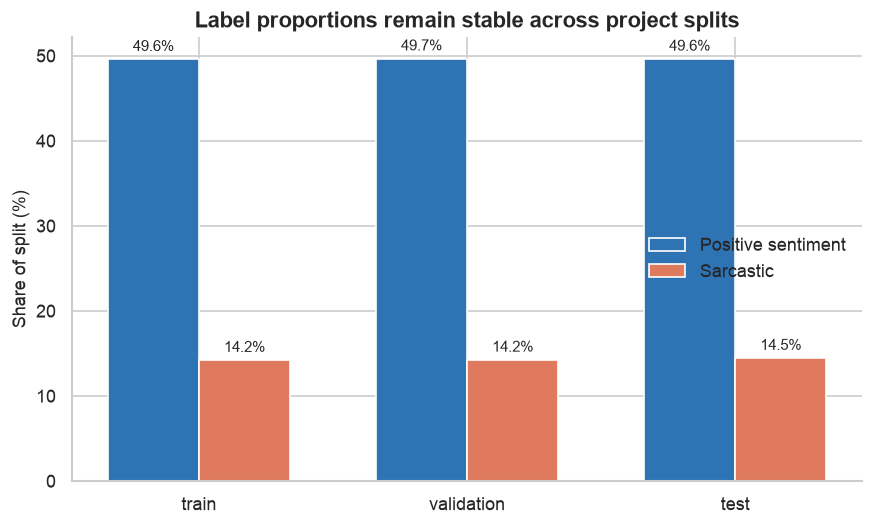

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(len(SPLIT_ORDER))
width = 0.34
ax.bar(x - width/2, split_label_balance["sentiment_positive_rate"] * 100, width, label="Positive sentiment", color="#2E74B5")
ax.bar(x + width/2, split_label_balance["sarcastic_rate"] * 100, width, label="Sarcastic", color="#E07A5F")
ax.set_xticks(x, SPLIT_ORDER)
ax.set_ylabel("Share of split (%)")
ax.set_title("Label proportions remain stable across project splits")
ax.legend(frameon=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)
sns.despine(ax=ax)
save_figure(fig, "label_proportions_by_split")
plt.show()

## 3. See how sample sizes differ

These heatmaps count every variety and source combination: first across all data, then inside each split. They show which comparisons have enough support and which ones need cautious wording. The same counts are saved as CSV.

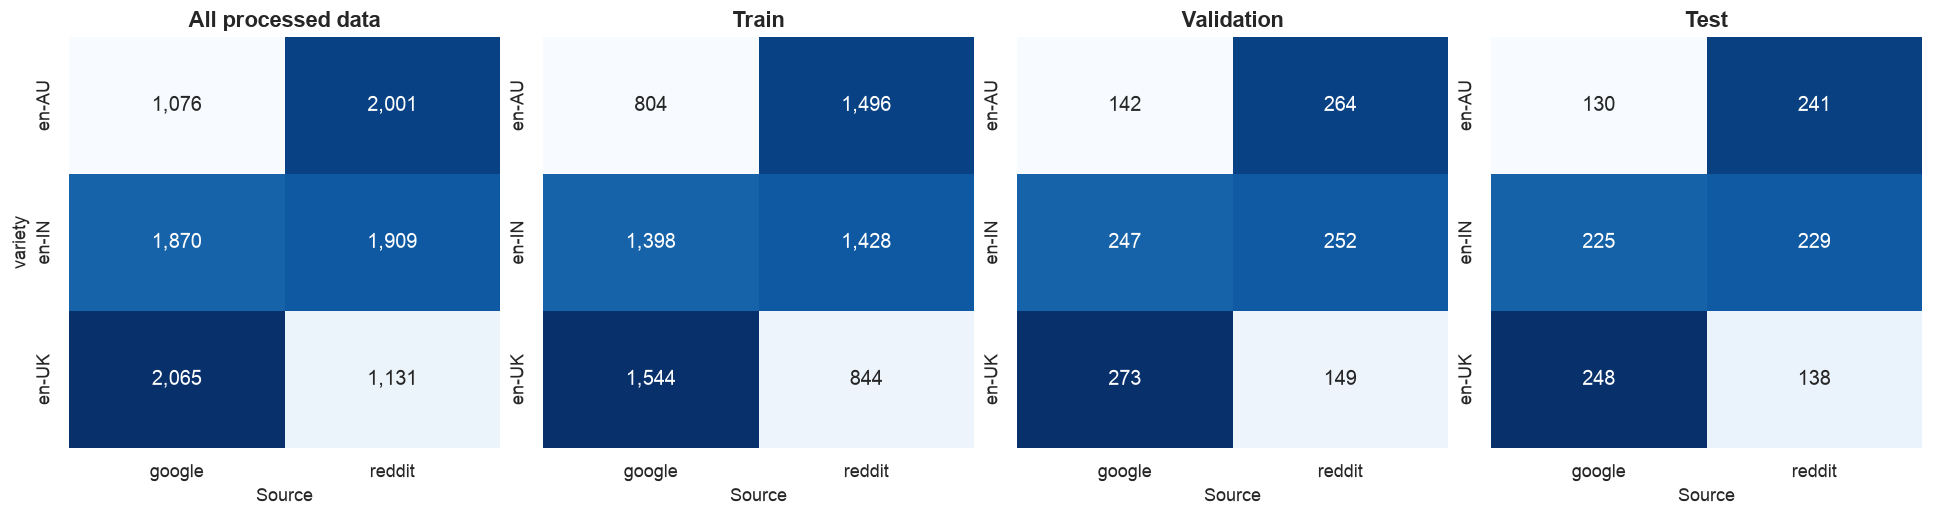

In [11]:
count_table = (
    df.groupby(["variety", "source"], observed=True)
      .size().unstack(fill_value=0)
      .reindex(index=VARIETY_ORDER, columns=SOURCE_ORDER)
)
count_table.to_csv(OUTPUT_DIR / "variety_source_sample_counts.csv")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), constrained_layout=True)
sns.heatmap(count_table, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("All processed data")
for index, split in enumerate(SPLIT_ORDER, start=1):
    table = (
        df[df["split"] == split]
          .groupby(["variety", "source"], observed=True)
          .size().unstack(fill_value=0)
          .reindex(index=VARIETY_ORDER, columns=SOURCE_ORDER, fill_value=0)
    )
    sns.heatmap(table, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[index])
    axes[index].set_title(split.title())
    axes[index].set_ylabel("")
for ax in axes:
    ax.set_xlabel("Source")
save_figure(fig, "variety_source_sample_count_heatmaps")
plt.show()

## 4. Compare text lengths

A median alone would hide the long tail, so we calculate several length statistics and plot the full distribution. The boxplot stops at the 99th percentile only for readability; the data itself is unchanged. Later models can use this result to explain their truncation limit.

,variety,source,n,mean,median,std,min,max,p25,p75,p90,p95,p99
0,en-AU,google,1076,63.67,51.0,47.60,1,464,33.0,80.0,122.0,151.0,240.75
1,en-AU,reddit,2001,52.46,28.0,89.29,1,1321,14.0,56.0,109.0,163.0,465.00
2,en-IN,google,1870,43.73,33.0,38.66,1,354,19.0,55.0,84.0,115.0,215.31
3,en-IN,reddit,1909,26.70,15.0,37.22,1,525,8.0,30.0,59.2,88.0,207.60
4,en-UK,google,2065,71.87,56.0,56.54,1,569,37.0,87.0,139.0,175.8,290.16
5,en-UK,reddit,1131,37.70,25.0,39.13,1,362,13.0,48.0,80.0,113.0,197.20


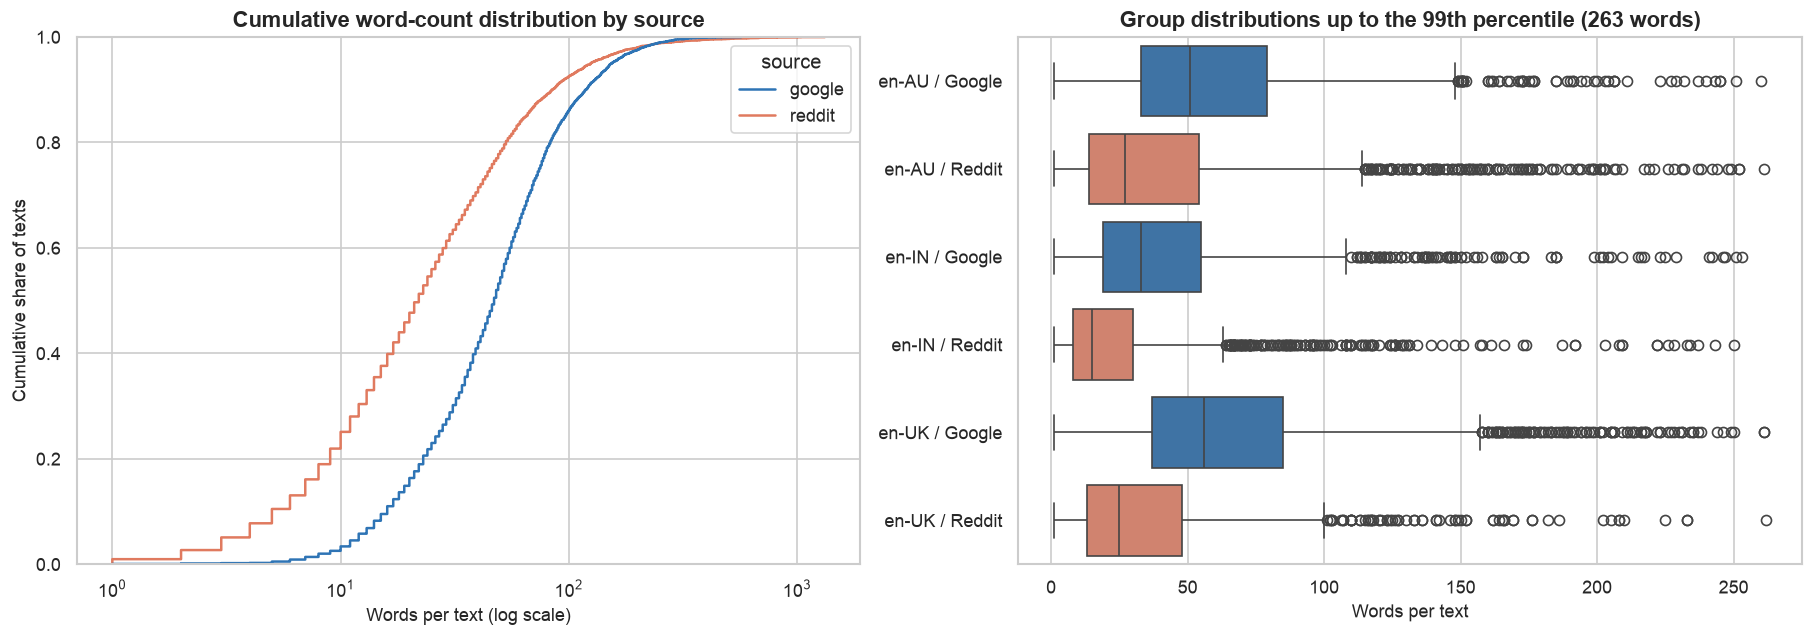

In [12]:
length_summary = (
    df.groupby(["variety", "source"], observed=True)["word_count"]
      .agg(n="size", mean="mean", median="median", std="std", min="min", max="max")
      .reset_index()
)
quantiles = (
    df.groupby(["variety", "source"], observed=True)["word_count"]
      .quantile([0.25, 0.75, 0.90, 0.95, 0.99])
      .unstack().reset_index()
      .rename(columns={0.25: "p25", 0.75: "p75", 0.90: "p90", 0.95: "p95", 0.99: "p99"})
)
length_summary = length_summary.merge(quantiles, on=["variety", "source"])
length_summary.to_csv(OUTPUT_DIR / "text_length_distribution_summary.csv", index=False)
display(length_summary.round(2))

plot_df = df.copy()
plot_df["segment"] = plot_df["variety"] + " / " + plot_df["source"].str.title()
segment_order = [f"{v} / {s.title()}" for v in VARIETY_ORDER for s in SOURCE_ORDER]
p99 = plot_df["word_count"].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), constrained_layout=True)
sns.ecdfplot(
    data=plot_df, x="word_count", hue="source",
    log_scale=True, ax=axes[0], palette={"google": "#2E74B5", "reddit": "#E07A5F"}
)
axes[0].set_title("Cumulative word-count distribution by source")
axes[0].set_xlabel("Words per text (log scale)")
axes[0].set_ylabel("Cumulative share of texts")

sns.boxplot(
    data=plot_df[plot_df["word_count"] <= p99], x="word_count", y="segment",
    order=segment_order, hue="source", dodge=False, legend=False,
    palette={"google": "#2E74B5", "reddit": "#E07A5F"}, ax=axes[1]
)
axes[1].set_title(f"Group distributions up to the 99th percentile ({p99:.0f} words)")
axes[1].set_xlabel("Words per text")
axes[1].set_ylabel("")
save_figure(fig, "text_length_distributions")
plt.show()

## 5. Look at early keyword patterns

This quick TF-IDF comparison finds words and short phrases that stand out in each training group. The ranked table is useful for later error analysis. It is not proof of a variety feature, since place names, topics and platform habits can also appear near the top.

In [13]:
train_df = df[df["split"] == "train"].copy()
train_df["segment"] = train_df["variety"] + " / " + train_df["source"].str.title()

word_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.95,
    max_features=18000,
    sublinear_tf=True,
)
word_matrix = word_vectorizer.fit_transform(train_df["text"])
word_names = np.asarray(word_vectorizer.get_feature_names_out())

keyword_rows = []
for segment in segment_order:
    mask = (train_df["segment"] == segment).to_numpy()
    group_mean = np.asarray(word_matrix[mask].mean(axis=0)).ravel()
    other_mean = np.asarray(word_matrix[~mask].mean(axis=0)).ravel()
    differential = group_mean - other_mean
    top_indices = differential.argsort()[-15:][::-1]
    for rank, feature_index in enumerate(top_indices, start=1):
        keyword_rows.append({
            "segment": segment,
            "rank": rank,
            "term": word_names[feature_index],
            "differential_tfidf": differential[feature_index],
        })

segment_keywords = pd.DataFrame(keyword_rows)
segment_keywords.to_csv(OUTPUT_DIR / "top_keywords_by_variety_source_train_only.csv", index=False)
keyword_display = segment_keywords.pivot(index="rank", columns="segment", values="term")
display(keyword_display)

segment,en-AU / Google,en-AU / Reddit,en-IN / Google,en-IN / Reddit,en-UK / Google,en-UK / Reddit
rank,,,,,,
1,great,don,good,hai,staff,people
2,food,australia,taste,india,food,fuck
3,staff,think,food,bhi,great,uk
4,service,government,place,don,friendly,labour
5,friendly,melbourne,quality,se,lovely,fucking
6,nice,ve,available,ki,service,don
7,ordered,sure,veg,bjp,nice,country
8,chips,australian,hotel,ke,did,tories
9,delicious,work,price,damn,drinks,shit


### Character n-gram variety baseline and feature inspection

A small character 3-5 gram classifier gives us an early variety baseline. We fit it on train, check it on validation, and save its score report, confusion matrix and strongest character patterns. It is a diagnostic, not a final test result.

Validation macro-F1: 0.712


,precision,recall,f1-score,support
en-AU,0.649,0.633,0.641,406.000
en-IN,0.797,0.812,0.804,499.000
en-UK,0.690,0.692,0.691,422.000
accuracy,0.719,0.719,0.719,0.719
macro avg,0.712,0.712,0.712,1327.000
weighted avg,0.718,0.719,0.718,1327.000


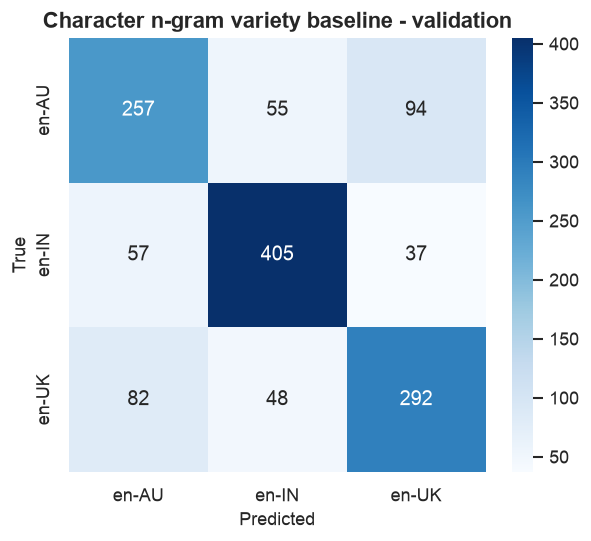

variety,en-AU,en-IN,en-UK
rank,,,
1,' aus',' ka',' a '
2,' au','ndia',' uk'
3,'stral','india','uk '
4,'trali','is ',' uk '
5,'ralia',' is ','pub'
6,' aust',' he ',' pub'
7,'rali','indi',' tor'
8,'tral','dia','ndo'
9,'austr',' bh','ovely'


In [14]:
train = df[df["split"] == "train"]
valid = df[df["split"] == "validation"]

char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=5,
    max_features=30000,
    sublinear_tf=True,
)
X_train_char = char_vectorizer.fit_transform(train["text"])
X_valid_char = char_vectorizer.transform(valid["text"])
char_model = LogisticRegression(max_iter=1500, class_weight="balanced", C=2.0)
char_model.fit(X_train_char, train["variety"])
valid_pred = char_model.predict(X_valid_char)

char_macro_f1 = f1_score(valid["variety"], valid_pred, average="macro")
char_report = pd.DataFrame(classification_report(
    valid["variety"], valid_pred, labels=VARIETY_ORDER, output_dict=True, zero_division=0
)).T
char_report.to_csv(OUTPUT_DIR / "char_ngram_variety_validation_report.csv")
print(f"Validation macro-F1: {char_macro_f1:.3f}")
display(char_report.round(3))

cm = confusion_matrix(valid["variety"], valid_pred, labels=VARIETY_ORDER)
fig, ax = plt.subplots(figsize=(5.6, 4.7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=VARIETY_ORDER, yticklabels=VARIETY_ORDER, ax=ax)
ax.set_title("Character n-gram variety baseline - validation")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
save_figure(fig, "char_ngram_variety_validation_confusion")
plt.show()

char_names = np.asarray(char_vectorizer.get_feature_names_out())
char_rows = []
for class_index, variety in enumerate(char_model.classes_):
    top_indices = char_model.coef_[class_index].argsort()[-20:][::-1]
    for rank, feature_index in enumerate(top_indices, start=1):
        char_rows.append({
            "variety": variety,
            "rank": rank,
            "char_ngram": repr(char_names[feature_index]),
            "coefficient": char_model.coef_[class_index, feature_index],
        })
top_char_ngrams = pd.DataFrame(char_rows)
top_char_ngrams.to_csv(OUTPUT_DIR / "top_character_ngrams_by_variety_train_only.csv", index=False)
display(top_char_ngrams.pivot(index="rank", columns="variety", values="char_ngram").head(15))

### Source-shortcut diagnostic

We also test how easily the text reveals Google versus Reddit. The score report, confusion matrix and associated terms show how strong that shortcut is. A very high score warns us that later models may learn platform style instead of the task we care about.

Source diagnostic validation macro-F1: 0.972


,precision,recall,f1-score,support
google,0.983,0.961,0.972,662.000
reddit,0.962,0.983,0.972,665.000
accuracy,0.972,0.972,0.972,0.972
macro avg,0.972,0.972,0.972,1327.000
weighted avg,0.972,0.972,0.972,1327.000


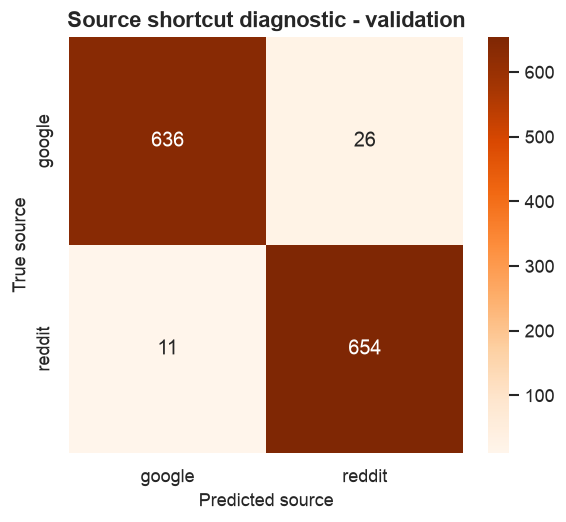

,google_associated,reddit_associated
0,food,don
1,good,that
2,place,he
3,was,re
4,staff,country
5,very,how
6,service,these
7,taste,government
8,great,why
9,and,shit


**Diagnostic conclusion:** source prediction macro-F1 is **0.972**, compared with **0.712** for the preliminary character n-gram variety baseline. The final project must test source/topic shortcuts rather than treating every variety score as linguistic evidence.

In [15]:
source_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=20000, sublinear_tf=True)),
    ("model", LogisticRegression(max_iter=1200, class_weight="balanced")),
])
source_pipeline.fit(train["text"], train["source"])
source_pred = source_pipeline.predict(valid["text"])
source_macro_f1 = f1_score(valid["source"], source_pred, average="macro")
source_report = pd.DataFrame(classification_report(
    valid["source"], source_pred, labels=SOURCE_ORDER, output_dict=True, zero_division=0
)).T
source_report.to_csv(OUTPUT_DIR / "source_diagnostic_validation_report.csv")
print(f"Source diagnostic validation macro-F1: {source_macro_f1:.3f}")
display(source_report.round(3))

source_cm = confusion_matrix(valid["source"], source_pred, labels=SOURCE_ORDER)
fig, ax = plt.subplots(figsize=(5.3, 4.5))
sns.heatmap(source_cm, annot=True, fmt="d", cmap="Oranges", xticklabels=SOURCE_ORDER, yticklabels=SOURCE_ORDER, ax=ax)
ax.set_title("Source shortcut diagnostic - validation")
ax.set_xlabel("Predicted source")
ax.set_ylabel("True source")
save_figure(fig, "source_diagnostic_validation_confusion")
plt.show()

src_vectorizer = source_pipeline.named_steps["tfidf"]
src_model = source_pipeline.named_steps["model"]
src_names = np.asarray(src_vectorizer.get_feature_names_out())
coef = src_model.coef_[0]
source_terms = pd.DataFrame({
    "google_associated": src_names[np.argsort(coef)[:15]],
    "reddit_associated": src_names[np.argsort(coef)[-15:][::-1]],
})
source_terms.to_csv(OUTPUT_DIR / "source_associated_terms_train_only.csv", index=False)
display(source_terms)

diagnostic_summary = {
    "char_ngram_variety_validation_macro_f1": float(char_macro_f1),
    "source_prediction_validation_macro_f1": float(source_macro_f1),
    "interpretation": "Source is much easier to predict than English variety, so the final evaluation needs source-aware and cross-source checks.",
}
(OUTPUT_DIR / "preliminary_diagnostic_summary.json").write_text(json.dumps(diagnostic_summary, indent=2), encoding="utf-8")
display(Markdown(
    f"**Diagnostic conclusion:** source prediction macro-F1 is **{source_macro_f1:.3f}**, "
    f"compared with **{char_macro_f1:.3f}** for the preliminary character n-gram variety baseline. "
    "The final project must test source/topic shortcuts rather than treating every variety score as linguistic evidence."
))

## 6. Count the sarcasm examples

Here we count sarcastic and non-sarcastic examples overall and for every useful grouping. All six tables are saved. Rates are always shown with counts, because a percentage can be misleading when only a few positive examples exist.

In [16]:
def binary_distribution(data, dimensions):
    grouped = (
        data.groupby(dimensions, observed=True)["sarcasm"]
            .agg(total="size", sarcastic="sum", rate="mean")
            .reset_index()
    )
    grouped["sarcastic"] = grouped["sarcastic"].astype(int)
    grouped["non_sarcastic"] = grouped["total"] - grouped["sarcastic"]
    return grouped[dimensions + ["total", "sarcastic", "non_sarcastic", "rate"]]

sarcasm_overall = pd.DataFrame([{
    "group": "overall",
    "total": len(df),
    "sarcastic": int(df["sarcasm"].sum()),
    "non_sarcastic": int((df["sarcasm"] == 0).sum()),
    "rate": df["sarcasm"].mean(),
}])
sarcasm_split = binary_distribution(df, ["split"])
sarcasm_variety = binary_distribution(df, ["variety"])
sarcasm_source = binary_distribution(df, ["source"])
sarcasm_cell = binary_distribution(df, ["variety", "source"])
sarcasm_full = binary_distribution(df, ["split", "variety", "source"])

tables = {
    "sarcasm_distribution_overall.csv": sarcasm_overall,
    "sarcasm_distribution_by_split.csv": sarcasm_split,
    "sarcasm_distribution_by_variety.csv": sarcasm_variety,
    "sarcasm_distribution_by_source.csv": sarcasm_source,
    "sarcasm_distribution_by_variety_source.csv": sarcasm_cell,
    "sarcasm_distribution_by_split_variety_source.csv": sarcasm_full,
}
for filename, table in tables.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)

display(Markdown("### Overall"))
display(with_percent_strings(sarcasm_overall, ["rate"]))
display(Markdown("### By project split"))
display(with_percent_strings(sarcasm_split, ["rate"]))
display(Markdown("### By English variety"))
display(with_percent_strings(sarcasm_variety, ["rate"]))
display(Markdown("### By source"))
display(with_percent_strings(sarcasm_source, ["rate"]))
display(Markdown("### Complete variety × source distribution"))
display(with_percent_strings(sarcasm_cell, ["rate"]))
display(Markdown("### Full split × variety × source support"))
display(with_percent_strings(sarcasm_full, ["rate"]))

### Overall

,group,total,sarcastic,non_sarcastic,rate
0,overall,10052,1432,8620,14.25%


### By project split

,split,total,sarcastic,non_sarcastic,rate
0,test,1211,175,1036,14.45%
1,train,7514,1068,6446,14.21%
2,validation,1327,189,1138,14.24%


### By English variety

...

,source,total,sarcastic,non_sarcastic,rate
0,google,5011,88,4923,1.76%
1,reddit,5041,1344,3697,26.66%


### Complete variety × source distribution

,variety,source,total,sarcastic,non_sarcastic,rate
0,en-AU,google,1076,73,1003,6.78%
1,en-AU,reddit,2001,841,1160,42.03%
2,en-IN,google,1870,14,1856,0.75%
3,en-IN,reddit,1909,257,1652,13.46%
4,en-UK,google,2065,1,2064,0.05%
5,en-UK,reddit,1131,246,885,21.75%


### Full split × variety × source support

,split,variety,source,total,sarcastic,non_sarcastic,rate
0,test,en-AU,google,130,7,123,5.38%
1,test,en-AU,reddit,241,102,139,42.32%
2,test,en-IN,google,225,2,223,0.89%
3,test,en-IN,reddit,229,34,195,14.85%
4,test,en-UK,google,248,0,248,0.00%
5,test,en-UK,reddit,138,30,108,21.74%
6,train,en-AU,google,804,56,748,6.97%
7,train,en-AU,reddit,1496,628,868,41.98%
8,train,en-IN,google,1398,10,1388,0.72%
9,train,en-IN,reddit,1428,190,1238,13.31%


### Show the sarcasm imbalance

The heatmap puts the imbalance in one view. Each square shows both the rate and raw positive count, so the tiny Google-positive groups are not hidden behind percentages.

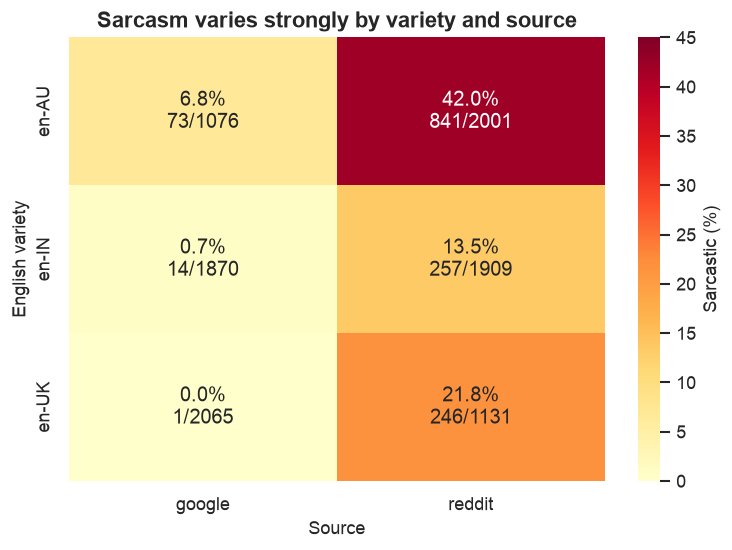

In [17]:
rate_matrix = sarcasm_cell.pivot(index="variety", columns="source", values="rate").reindex(index=VARIETY_ORDER, columns=SOURCE_ORDER)
positive_matrix = sarcasm_cell.pivot(index="variety", columns="source", values="sarcastic").reindex(index=VARIETY_ORDER, columns=SOURCE_ORDER)
total_matrix = sarcasm_cell.pivot(index="variety", columns="source", values="total").reindex(index=VARIETY_ORDER, columns=SOURCE_ORDER)
annotations = rate_matrix.copy().astype(object)
for variety in VARIETY_ORDER:
    for source in SOURCE_ORDER:
        annotations.loc[variety, source] = f"{rate_matrix.loc[variety, source]:.1%}\n{positive_matrix.loc[variety, source]}/{total_matrix.loc[variety, source]}"

fig, ax = plt.subplots(figsize=(7.2, 4.8))
sns.heatmap(rate_matrix * 100, annot=annotations, fmt="", cmap="YlOrRd", vmin=0, vmax=45, cbar_kws={"label": "Sarcastic (%)"}, ax=ax)
ax.set_title("Sarcasm varies strongly by variety and source")
ax.set_xlabel("Source")
ax.set_ylabel("English variety")
save_figure(fig, "sarcasm_rate_by_variety_source")
plt.show()

## 7. Decide what the sarcasm data can support

The next table turns those counts into guidance for each segment. Sarcasm modelling, evaluation and the application can read it directly. These cut-offs are cautious rules for this project, not universal statistical laws:

- `test positives = 0`: positive-class recall/F1/PR-AUC are not estimable.
- `train positives < 20`: do not train a standalone segment model.
- `test positives < 5`: report support and descriptive behaviour only; avoid comparative claims.
- Every subgroup metric must display positive and total support.

In [18]:
support = sarcasm_full.pivot_table(
    index=["variety", "source"], columns="split", values=["sarcastic", "total"], aggfunc="first"
).reset_index()
support.columns = ["_".join([str(part) for part in col if str(part)]) if isinstance(col, tuple) else col for col in support.columns]

def support_recommendation(row):
    train_pos = row["sarcastic_train"]
    test_pos = row["sarcastic_test"]
    if train_pos < 20 and test_pos == 0:
        return "No standalone model; use shared global model, show limited-evidence warning, report false-positive behaviour only"
    if train_pos < 20:
        return "No standalone model; shared model only, descriptive subgroup metrics with support"
    if test_pos < 5:
        return "Shared model; subgroup comparison is unstable and descriptive only"
    return "Shared model is primary; subgroup metrics allowed with support and uncertainty"

support["recommendation"] = support.apply(support_recommendation, axis=1)
support.to_csv(OUTPUT_DIR / "sarcasm_segment_support_recommendations.csv", index=False)
display(support)

assert int(support.query("variety == 'en-UK' and source == 'google'")["sarcastic_train"].iloc[0]) == 1
assert int(support.query("variety == 'en-UK' and source == 'google'")["sarcastic_validation"].iloc[0]) == 0
assert int(support.query("variety == 'en-UK' and source == 'google'")["sarcastic_test"].iloc[0]) == 0

,variety,source,sarcastic_test,sarcastic_train,sarcastic_validation,total_test,total_train,total_validation,recommendation
0,en-AU,google,7,56,10,130,804,142,Shared model is primary; subgroup metrics allo...
1,en-AU,reddit,102,628,111,241,1496,264,Shared model is primary; subgroup metrics allo...
2,en-IN,google,2,10,2,225,1398,247,"No standalone model; shared model only, descri..."
3,en-IN,reddit,34,190,33,229,1428,252,Shared model is primary; subgroup metrics allo...
4,en-UK,google,0,1,0,248,1544,273,"No standalone model; use shared global model, ..."
5,en-UK,reddit,30,183,33,138,844,149,Shared model is primary; subgroup metrics allo...


### What the sarcasm modelling work should do

The Google data needs special care: it has only 88 sarcastic examples in total. `en-UK Google` has one positive example in train and none in validation or test; `en-IN Google` is also very sparse.

1. Train one shared sarcasm model across all varieties and sources. Do not train separate Google models for en-UK or en-IN.
2. Compare a normal baseline with a class-weighted version. Calculate weights from the training split only.
3. Choose any probability or review threshold on validation only, then run the test set once.
4. Report macro-F1, sarcastic precision/recall/F1, PR-AUC, balanced accuracy and confusion matrices. Accuracy alone will hide the imbalance.
5. Show overall, per-variety and per-source results. Add `variety × source` results only with their positive and total counts.
6. For `en-UK Google` test, positive-class recall, F1 and PR-AUC are not measurable because there are no positive cases. Show them as `N/A`, not zero. Report false positives, false-positive rate, specificity and predicted-positive rate instead.
7. In the application, use the shared model for sparse Google segments and show a short `Limited segment evidence` warning. Send predicted-positive cases to human review rather than presenting them as certain.

## 8. What the EDA means for the system design

The results point to a review tool for customer and social-media text, not a nationality detector:

```text
Single text or batch CSV
        |
        v
Schema/privacy validation ---- known source and optional market context
        |
        v
English-variety classifier ---- calibrated probabilities
        |
        +---- low confidence ---> global fallback + human-review flag
        |
        v
Global sentiment/sarcasm models
        +---- compare with variety-aware or routed models
        |
        v
Source-aware dashboard
        +---- variety/source support shown
        +---- model disagreement shown
        +---- limited-evidence warnings
        +---- review queue and export
```

Why this architecture follows from the EDA:

- Unequal `variety × source` counts require support-aware dashboards and evaluation.
- Strong source-specific label rates require per-source metrics and shortcut diagnostics.
- Severe sarcasm imbalance requires macro/positive-class metrics, class weighting and threshold evaluation.
- Sparse segments require shared models, fallback behaviour and honest reliability warnings.
- Long-tailed text lengths require documented truncation/feature decisions and length-stratified error analysis.

The next steps and role-based work packages are in [`LATER_PLAN.md`](../LATER_PLAN.md).

## 9. Files created by this notebook

The final list is a quick check that everything was written. Later code can read the CSV tables directly, and every figure is available as both PNG and SVG under:

`outputs/eda/`

The prepared task files live under `outputs/data/by_task/`. Modelling can use them as they are; evaluation should join predictions by `id`; and the application should use the saved support table when it decides whether to show a limited-evidence warning.

In [19]:
# Display all processed datasets and EDA outputs created by the notebook.
generated = []

for folder in [PROCESSED_DIR, OUTPUT_DIR]:
    generated.extend(
        path.relative_to(ROOT).as_posix()
        for path in folder.rglob("*")
        if path.is_file() and path.name != ".gitkeep"
    )

generated = sorted(generated)

print(f"Generated {len(generated)} reusable files:\n")
print("\n".join(f"- {path}" for path in generated))

Generated 45 reusable files:

- data/processed/audit/removed_rows.csv
- data/processed/by_task/sarcasm/test.csv
- data/processed/by_task/sarcasm/train.csv
- data/processed/by_task/sarcasm/validation.csv
- data/processed/by_task/sentiment/test.csv
- data/processed/by_task/sentiment/train.csv
- data/processed/by_task/sentiment/validation.csv
- data/processed/by_task/variety/test.csv
- data/processed/by_task/variety/train.csv
- data/processed/by_task/variety/validation.csv
- data/processed/dataset_v1.csv
- data/processed/quality_report.json
- data/processed/test.csv
- data/processed/train.csv
- data/processed/validation.csv
- data/processed/validation_report.json
- outputs/eda/char_ngram_variety_validation_report.csv
- outputs/eda/figures/char_ngram_variety_validation_confusion.png
- outputs/eda/figures/char_ngram_variety_validation_confusion.svg
- outputs/eda/figures/label_proportions_by_split.png
- outputs/eda/figures/label_proportions_by_split.svg
- outputs/eda/figures/sarcasm_rate_by_